# Week 8 Assignment: Exploring the Auto MPG Dataset

In this assignment, I will clean and explore the Auto MPG dataset. I will also create charts to examine the distribution of cylinders and relationships between different vehicle measurements.



In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Loading the Dataset

The Auto MPG dataset originally comes from the UCI Machine Learning Repository. I loaded a copy of the dataset directly from a GitHub repository so the code can be reproduced. I used the provided attribute information to name the columns.

Original source: [UCI Auto MPG Dataset](https://archive.ics.uci.edu/dataset/9/auto+mpg)

Data file used: [Auto MPG Dataset on GitHub](https://github.com/fvazqu/Auto-MPG-Dataset)



In [5]:
url = url = "https://raw.githubusercontent.com/fvazqu/Auto-MPG-Dataset/master/auto-mpg.data"
column_names = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    
    
    "origin",
    "car_name"
]

cars = pd.read_csv(url, sep=r"\s+", names=column_names)

cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## Reviewing and Cleaning the Data

I reviewed the dataset to check the column names, data types, and missing values. The horsepower column contains question marks where values are missing, so I replaced them with a pandas missing value and converted the column to numeric.


In [6]:
cars.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [7]:
cars["horsepower"] = cars["horsepower"].replace("?", pd.NA)
cars["horsepower"] = pd.to_numeric(cars["horsepower"])

cars["horsepower"].isna().sum()


6

After replacing the question marks, there are 6 missing values in the horsepower column. These values will be ignored when creating the horsepower scatterplot.


## Converting the Origin Values

The origin column uses the numbers 1, 2, and 3. I replaced these numbers with USA, Asia, and Europe to make the data easier to understand.


In [8]:
cars["origin"] = cars["origin"].replace({
    1: "USA",
    2: "Asia",
    3: "Europe"
})

cars["origin"].value_counts()


origin
USA       249
Europe     79
Asia       70
Name: count, dtype: int64

## Distribution of Cylinders

This bar chart shows how many cars have each number of cylinders.


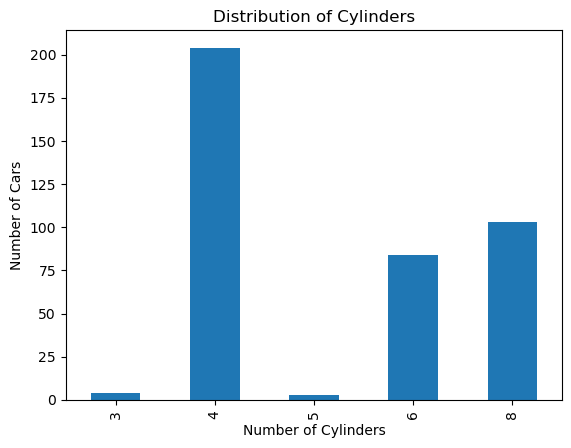

In [9]:
cars["cylinders"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Cylinders")
plt.xlabel("Number of Cylinders")
plt.ylabel("Number of Cars")
plt.show()


Four-cylinder cars are the most common, with 204 cars. The dataset also contains 103 eight-cylinder cars and 84 six-cylinder cars. Three-cylinder and five-cylinder cars are much less common.


## Horsepower and Weight

This scatterplot shows the relationship between a car's horsepower and weight.



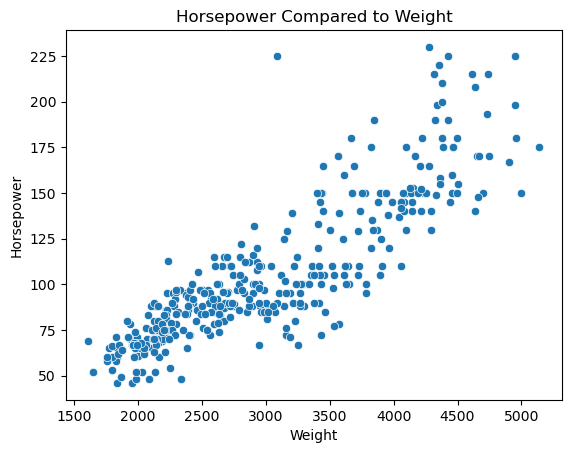

In [11]:
sns.scatterplot(data=cars, x="weight", y="horsepower")

plt.title("Horsepower Compared to Weight")
plt.xlabel("Weight")
plt.ylabel("Horsepower")
plt.show()


The scatterplot shows a positive relationship between weight and horsepower. In general, heavier cars tend to have more horsepower, although there are some differences between individual cars.


## Does Average MPG Differ by Origin?

I wanted to see whether cars from different origins have different average miles per gallon.


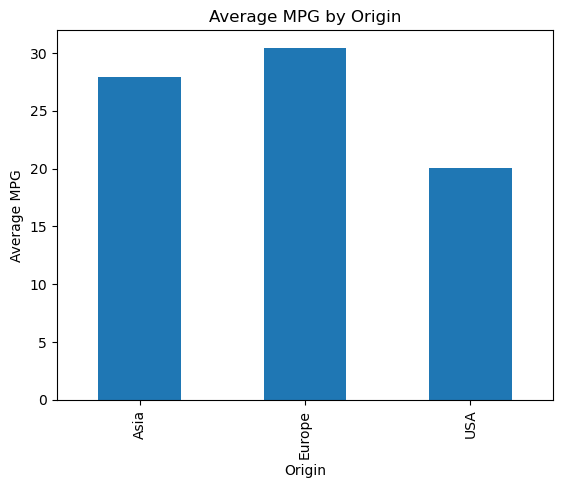

In [10]:
average_mpg = cars.groupby("origin")["mpg"].mean()

average_mpg.plot(kind="bar")

plt.title("Average MPG by Origin")
plt.xlabel("Origin")
plt.ylabel("Average MPG")
plt.show()


The chart shows that average MPG differs by origin. European cars have the highest average MPG, followed by Asian cars, while cars from the USA have the lowest average MPG in this dataset.
